# Підготовка даних для регресії: тривалість впливу ДТП (`Duration_Minutes`)

**Задача:** за обставинами ДТП (місце, час, погода, дорога) прогнозувати, як довго ДТП впливає на рух.
**Результат ноутбука:** готові до навчання train / valid / test у `data/processed/regression/` + `metadata.json` з усіма параметрами обробки. **Моделі тут не навчаються.**

Кожен крок оформлено як **Рішення → Аргументи → Перевірка на даних**. Аргументи спираються на попереднє дослідження (базові моделі, покращений препроцесинг, відбір ознак), підсумок якого наведено в тексті.

| # | Крок | Ключове рішення |
|---|---|---|
| 1 | Первинна обробка | конвеєр `main.py` без змін |
| 2 | Повернення колонок | `Source`, `Street` з сирих даних |
| 3 | Повтори однієї події | «знімки» однієї ДТП від того самого джерела → один запис |
| 4 | Невідомі значення | записи з вигаданими (заповненими) значеннями — видалити; штиль → швидкість 0; опади — прибрати як ознаку |
| 5 | Ціль | `log1p(Duration)`, область 1 хв … Q99, без заглушок 360 хв |
| 6 | Витік | без `End_Time`, `Severity`, `Description` |
| 7 | Ознаки | нормалізація категорій, взаємодії часу, `Source_Year`, тип дороги |
| 8 | Розбиття | групове «місце + день», 70 / 10 / 20 |
| 9 | Викиди ознак | clip 0.5–99.5% (train), `log1p` для скошених |
| 10 | Високо-кардинальні ознаки | out-of-fold target encoding (`sklearn`) + частоти |
| 11 | Відбір ознак | фільтр за зв'язком із ціллю (η) і надлишковістю |
| 12 | Кодування | one-hot, квантильні біни, стандартизація, `VarianceThresholdSelector` |
| 13 | Експорт | parquet + metadata |

## 0. Налаштування

In [1]:
import os
import sys
import json
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
java_home = os.environ.get("JAVA_HOME")
if not java_home or not (Path(java_home) / "bin").exists():
    print("[WARNING] JAVA_HOME не задано або вказує на неіснуючу теку — PySpark 4.x потребує JDK 17 або 21.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, QuantileDiscretizer,
                                VarianceThresholdSelector)
from pyspark.ml.functions import vector_to_array
from pyspark.ml.stat import Correlation

from config import DATA_PATH
from schemas.raw_schema import raw_schema
from modules.extraction import load_data
from modules.parsing import parse_and_transform_features
from modules.feature_selection import select_features
from modules.data_quality import remove_duplicates, handle_missing_values
from modules.ml_features import (ROAD_BOOL, DESC_PATTERNS, raw_extras, engineer_features, incident_group,
                                 snapshot_groups, is_placeholder_duration, clip_and_log, encode_locations,
                                 cramers_v, eta)

TASK = "regression"
SEED = 42
N_FOLDS = 5                     # фолди out-of-fold target encoding
TE_SMOOTHING = 30.0             # згладжування target encoding
CLIP_Q = (0.005, 0.995)         # перцентилі вінсоризації ознак
N_BINS = 10                     # квантильні біни (і для оцінки зв'язку, і як ознаки)
THR_ASSOC = 0.01       # нижче — зв'язок з ціллю вважається відсутнім
THR_REDUNDANT = 0.9     # вище — дві ознаки вважаються дублікатами
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / TASK

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

spark = (
    SparkSession.builder
    .appName(f"US-Accidents-{TASK}-prep")
    .master("local[*]")
    .config("spark.driver.memory", "16g")
    .config("spark.driver.host", "localhost")
    .config("spark.sql.shuffle.partitions", "48")
    .config("spark.local.dir", str(PROJECT_ROOT / "spark-tmp"))   # shuffle на диск E:, не в системний TEMP
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.driver.maxResultSize", "6g")                 # toPandas для target encoding і оцінки зв'язку
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.debug.maxToStringFields", "1000")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
DECISIONS = []   # журнал рішень — зведення в кінці ноутбука
print("Spark", spark.version)

Spark 4.1.1


## 1. Первинна обробка — конвеєр `main.py`

**Рішення:** використати модулі проєкту без змін: читання за `raw_schema` → видалення смислових дублікатів → `Year/Month/DayOfWeek/Hour`, `Duration_Minutes`, `Zipcode_Base` → `Light_Level` і видалення колонок (`select_features`) → повторне видалення дублікатів → заповнення пропусків погоди.

**Аргументи:** ML-дані мають відповідати даним OLAP-частини проєкту; модулі вже перевірені командою. Те, чого конвеєру бракує для ML, додаємо наступними кроками, не змінюючи модулі (щоб не зачепити `main.py`).

In [2]:
t0 = time.time()
raw_df = load_data(spark, DATA_PATH, raw_schema)
n_raw = raw_df.count()
base_df = remove_duplicates(raw_df)
base_df = parse_and_transform_features(base_df)
base_df = select_features(base_df)
base_df = remove_duplicates(base_df)
base_df = handle_missing_values(base_df)


--- Очищення дублікатів ---


Видалено записів: 117695 (1.5229%)



--- Очищення дублікатів ---


Видалено записів: 23204 (0.3049%)

--- Опрацювання пропусків ---


Очищення завершено. Видалено рядків: 7925


## 2. Повернення колонок, які видаляє `select_features`

**Рішення:** приєднати за `ID` з сирих даних:
* `Source` — постачальник даних (Source1 / Source2 / Source3);
* `Street_Type` — тип дороги, виділений з назви вулиці (Interstate, US_Highway, Expressway, Route_Hwy, Avenue_Blvd, Local_Street, Other, Unknown);
* нормалізовану назву вулиці — як ключ для target encoding (крок 10);
* прапорці ключових слів `Description` — **лише для перевірки витоку** (крок 6).

**Аргументи:** у дослідженні `Source × рік` виявилась **найважливішою ознакою** для обох задач (permutation importance: +0.70 log-loss класифікації, −0.51 R² регресії при перемішуванні), бо джерела по-різному фіксують і тяжкість, і час завершення. Тип дороги суттєво змінює розподіл цілей (див. нижче). Для OLAP ці колонки зайві, тому `select_features` їх видаляє — для ML повертаємо.

In [3]:
df = engineer_features(base_df.join(raw_extras(raw_df), "ID", "left").filter(F.col("Duration_Minutes") > 0))
df = df.persist(StorageLevel.MEMORY_AND_DISK)
n_rows = df.count()
assert n_rows == df.select(F.countDistinct("ID")).first()[0], "join за ID розмножив рядки"
print(f"Сирих записів: {n_raw:,} → після первинної обробки: {n_rows:,} ({time.time() - t0:.0f} c)")
DECISIONS.append(("1–2. Первинна обробка + повернення колонок", "конвеєр main.py; +Source, Street_Type, ключ вулиці",
                  f"{n_raw:,} → {n_rows:,} рядків"))

Сирих записів: 7,728,394 → після первинної обробки: 7,579,570 (304 c)


## 3. Повтори однієї події від того самого джерела («знімки»)

`remove_duplicates` з `main.py` видаляє лише записи, ідентичні в **усіх** полях. Але датасет зібрано багаторазовим опитуванням API сервісів трафіку: поки подія триває, сервіс оновлює її (подовжує / скорочує час завершення, переоцінює тяжкість, змінює опис), і збирач зберігав **кожну версію як новий запис з новим `ID`**. Такі версії відрізняються хоча б одним полем, тому `main.py` їх не прибирає.

**Критерій «знімка»:** те саме джерело, те саме місце (координати до 0.0001° ≈ 11 м), та сама вулиця, **той самий напрямок руху** (з опису) і початок з паузою ≤ 15 хв від попереднього запису. Протилежні напрямки — це окремі затори, їх не об'єднуємо. Реалізація — віконні функції Spark (`Window`, `lag`, кумулятивна сума).

In [4]:
df = snapshot_groups(df).persist(StorageLevel.MEMORY_AND_DISK)
in_group = F.col("Snapshot_Size") > 1
snap_stats = (df.groupBy("Source").agg(
    F.count("*").alias("записів"),
    F.sum(in_group.cast("int")).alias("у групах знімків"),
    F.countDistinct(F.when(in_group, F.col("Snapshot_Group"))).alias("груп знімків"),
    F.sum((F.col("Snapshot_Severities") > 1).cast("int")).alias("у групах із суперечливою тяжкістю"))
    .toPandas().set_index("Source").sort_index())
snap_stats.loc["Разом"] = snap_stats.sum()
snap_stats["зайвих записів"] = snap_stats["у групах знімків"] - snap_stats["груп знімків"]
snap_stats["% зайвих"] = (100 * snap_stats["зайвих записів"] / snap_stats["записів"]).round(2)
snap_stats

,записів,у групах знімків,груп знімків,у групах із суперечливою тяжкістю,зайвих записів,% зайвих
Source,,,,,,
Source1,4183409,766037,323249,125043,442788,10.58
Source2,3298936,33028,16215,2039,16813,0.51
Source3,97225,874,430,53,444,0.46
Разом,7579570,799939,339894,127135,460045,6.07


In [5]:
# Що саме відрізняється між знімками однієї групи
diff = (df.filter(in_group).groupBy("Snapshot_Group").agg(
            F.countDistinct("Start_Time").alias("n_start"), F.countDistinct("End_Time").alias("n_end"),
            F.max("Snapshot_Severities").alias("n_sev"), F.countDistinct("Distance(mi)").alias("n_dist"))
        .agg(F.round(100 * F.avg((F.col("n_start") == 1).cast("double")), 1).alias("% груп: однаковий початок"),
             F.round(100 * F.avg((F.col("n_dist") == 1).cast("double")), 1).alias("% груп: однакова протяжність"),
             F.round(100 * F.avg((F.col("n_end") == 1).cast("double")), 1).alias("% груп: однаковий кінець"),
             F.round(100 * F.avg((F.col("n_sev") == 1).cast("double")), 1).alias("% груп: однакова тяжкість"))
        .toPandas())
display(diff.T.rename(columns={0: "значення"}))

example = df.filter(F.col("Snapshot_Severities") > 1).orderBy("Source", "Snapshot_Group").select("Snapshot_Group").limit(1).collect()
if example:
    print("Приклад групи знімків однієї події з різною тяжкістю:")
    display(df.filter(F.col("Snapshot_Group") == example[0][0])
              .select("ID", "Source", "Severity", "Start_Time", "End_Time", "Duration_Minutes", "Distance(mi)",
                      "Street_Norm", "Desc_Direction", "Desc_Closed")
              .orderBy("End_Time").toPandas())

,значення
% груп: однаковий початок,78.8
% груп: однакова протяжність,77.8
% груп: однаковий кінець,17.1
% груп: однакова тяжкість,83.1


Приклад групи знімків однієї події з різною тяжкістю:


,ID,Source,Severity,Start_Time,End_Time,Duration_Minutes,Distance(mi),Street_Norm,Desc_Direction,Desc_Closed
0,A-4093926,Source1,2,2022-11-04 22:26:00,2022-11-04 23:41:00,75.0,0.299,ga-403 n,N,1
1,A-4592379,Source1,4,2022-11-04 22:26:00,2022-11-04 23:41:00,75.0,0.299,ga-403 n,N,1


Знімки однієї групи майже завжди мають **той самий початок і протяжність**, але **різний час завершення**, а частина — й різну тяжкість (приклад вище — та сама подія з різною тяжкістю). Тобто це версії однієї ДТП, а не різні ДТП.

**Рішення:** з кожної групи знімків залишаємо **один запис — версію з найпізнішим часом завершення**.

**Аргументи:**
* одна ДТП, записана кілька разів, мала б у навчанні й у метриках у кілька разів більшу вагу, ніж інші;
* версія з найпізнішим `End_Time` — **остаточний стан** події: ранні версії містять проміжну оцінку часу завершення, а ціль регресії — саме повна тривалість;
* розбіжності тяжкості між знімками для цієї задачі не важливі (`Severity` — не ціль і не ознака);
* протилежні напрямки руху не об'єднуються — затор у кожному напрямку свій.

In [6]:
n_before = n_rows
latest = Window.partitionBy("Snapshot_Group").orderBy(F.desc("End_Time"), F.desc("ID"))
dedup = (df.withColumn("_r", F.row_number().over(latest)).filter(F.col("_r") == 1).drop("_r")
           .persist(StorageLevel.MEMORY_AND_DISK))
n_rows = dedup.count()
df.unpersist()
df = dedup
print(f"Записів: {n_before:,} → {n_rows:,} (прибрано {n_before - n_rows:,} повторних знімків, {100 * (n_before - n_rows) / n_before:.2f}%)")
DECISIONS.append(("3. Знімки однієї події", "з групи знімків — версія з найпізнішим End_Time", f"{n_before:,} → {n_rows:,} рядків"))

Записів: 7,579,570 → 7,119,525 (прибрано 460,045 повторних знімків, 6.07%)


## 4. Невідомі та «заповнені» значення

`handle_missing_values` з `main.py` заповнює пропуски погоди **медіанами**, невідомі категорії — значенням `"Unknown"`, а `select_features` перетворює невідомі twilight-значення на **«ніч»**. Для OLAP-агрегатів це прийнятно, але для моделі такі значення **вигадані**: вона не відрізнить «температура 64 °F» від «температура невідома, підставлено медіану» і вчитиметься на шумі.

Тому кожен вид невідомих значень розглядаємо як **кандидат на видалення**. Що саме було невідомим, визначаємо за прапорцями `Missing_*`, узятими з **сирих** даних (крок 2), — після заповнення цього вже не видно.

In [7]:
calm = F.col("Wind_Dir") == "CALM"
station_missing = (F.greatest(*[F.col(f"Missing_{c}") for c in ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)"]],
                              F.col("Missing_Weather_Condition"), F.col("Missing_Wind_Direction")) == 1) \
                  | (F.col("Weather_Condition") == "N/A Precipitation")
UNKNOWN_KINDS = {
    "немає даних метеостанції (погода → медіани / Unknown)": station_missing,
    "невідома швидкість вітру при штилі (Calm)": (F.col("Missing_Wind_Speed(mph)") == 1) & calm,
    "невідома швидкість вітру, напрямок відомий": (F.col("Missing_Wind_Speed(mph)") == 1) & ~calm & ~station_missing,
    "невідомий рівень освітленості (twilight → «ніч»)": F.col("Missing_Twilight") == 1,
    "невідома вулиця (Street_Type = Unknown)": F.col("Street_Type") == "Unknown",
    "невідомі опади (→ 0 / медіана)": F.col("Missing_Precipitation(in)") == 1,
}
target_expr = (F.when((F.col("Duration_Minutes") >= 1) & ~is_placeholder_duration(F.col("Duration_Minutes")),
                      F.log1p("Duration_Minutes")) if TASK == "regression" else F.col("Severity"))
flags_pd = df.select(*[e.cast("int").alias(n) for n, e in UNKNOWN_KINDS.items()], target_expr.alias("target"),
                     "Year").toPandas()
rows = []
for name in UNKNOWN_KINDS:
    has = flags_pd[name] == 1
    if TASK == "regression":
        sub = flags_pd[flags_pd["target"].notna()]
        link = eta(sub[name], sub["target"])
        diff = f"сер. log-тривалість: {sub.loc[sub[name] == 1, 'target'].mean():.3f} проти {sub.loc[sub[name] == 0, 'target'].mean():.3f}"
    else:
        link = cramers_v(flags_pd[name], flags_pd["target"])
        diff = (f"Severity 4: {100 * (flags_pd.loc[has, 'target'] == 4).mean():.2f}% проти "
                f"{100 * (flags_pd.loc[~has, 'target'] == 4).mean():.2f}%")
    rows.append({"вид невідомого значення": name, "записів": int(has.sum()), "% записів": round(100 * has.mean(), 3),
                 "зв'язок з ціллю": round(link, 4), "ціль: з прапорцем / без": diff})
unknown_table = pd.DataFrame(rows).set_index("вид невідомого значення")
unknown_table

,записів,% записів,зв'язок з ціллю,ціль: з прапорцем / без
вид невідомого значення,,,,
немає даних метеостанції (погода → медіани / Unknown),242531,3.407,0.0190,сер. log-тривалість: 4.289 проти 4.206
невідома швидкість вітру при штилі (Calm),365090,5.128,0.1500,сер. log-тривалість: 3.667 проти 4.235
"невідома швидкість вітру, напрямок відомий",12466,0.175,0.0284,сер. log-тривалість: 3.643 проти 4.209
невідомий рівень освітленості (twilight → «ніч»),18634,0.262,0.0256,сер. log-тривалість: 4.596 проти 4.208
невідома вулиця (Street_Type = Unknown),9250,0.130,0.0095,сер. log-тривалість: 4.413 проти 4.208
невідомі опади (→ 0 / медіана),2152093,30.228,0.3547,сер. log-тривалість: 3.747 проти 4.381


In [8]:
# Докази для двох особливих випадків: швидкість вітру при штилі та опади за роками
wind = df.select(calm.alias("штиль (Calm)"), (F.col("Missing_Wind_Speed(mph)") == 1).alias("швидкість невідома"),
                 F.when(F.col("Missing_Wind_Speed(mph)") == 0, F.col("Wind_Speed(mph)")).alias("відома швидкість"))
display(wind.groupBy("штиль (Calm)", "швидкість невідома")
        .agg(F.count("*").alias("записів"), F.min("відома швидкість").alias("min відомої швидкості"),
             F.max("відома швидкість").alias("max відомої швидкості")).orderBy("штиль (Calm)", "швидкість невідома").toPandas())
display(flags_pd.groupby("Year")["невідомі опади (→ 0 / медіана)"].mean().mul(100).round(1)
        .to_frame("% записів з невідомими опадами").T)

,штиль (Calm),швидкість невідома,записів,min відомої швидкості,max відомої швидкості
0,False,False,5711943,0.0,1087.0
1,False,True,177604,NaN,NaN
2,True,False,864888,0.0,0.0
3,True,True,365090,NaN,NaN


Year,2016,2017,2018,2019,2020,2021,2022,2023
% записів з невідомими опадами,90.9,88.0,86.7,22.9,5.1,4.1,3.6,4.4


**Рішення:**

| Вид невідомого значення | Рішення | Аргументи |
|---|---|---|
| немає даних метеостанції | **видалити записи** | температура, вологість, тиск, видимість, погода, напрямок вітру — вигадані (медіана / Unknown); зазвичай бракує всього набору одразу; ~2–3% записів; розподіл цілі на них майже такий самий (зв'язок ≈ 0.01–0.02), тож видалення не зсуває вибірку. Сюди ж — `Weather_Condition = "N/A Precipitation"` (теж «невідомо») |
| швидкість вітру невідома при **штилі** | **відновити 0**, не видаляти | у всіх записах зі штилем і відомою швидкістю вона рівно 0 — тобто «невідома» тут означає «0», а `handle_missing_values` помилково ставив медіану (~7 mph) |
| швидкість вітру невідома, напрямок відомий | **видалити записи** | справді невідома; < 0.5% записів |
| невідомий twilight | **видалити записи** | `Light_Level` мовчки став «ніч» — хибне значення; ~0.3% записів |
| невідома вулиця | **видалити записи** | тип дороги і target encoding вулиці неможливі; ~0.1% записів |
| невідомі опади | **прибрати ознаку `Precipitation`**, записи залишити | невідомі в ~29% записів, а за 2016–2018 рр. — у ~90%: заповнений «0» не відрізнити від справжнього «опадів немає». Видалити стільки записів не можна (зникли б цілі роки), а сама ознака у дослідженні не давала внеску; інформацію про дощ / сніг дає `Weather_Group` |

Після цього категорій `Unknown` в ознаках не лишається.

In [9]:
n_before = n_rows
drop_rule = (UNKNOWN_KINDS["немає даних метеостанції (погода → медіани / Unknown)"]
             | UNKNOWN_KINDS["невідома швидкість вітру, напрямок відомий"]
             | UNKNOWN_KINDS["невідомий рівень освітленості (twilight → «ніч»)"]
             | UNKNOWN_KINDS["невідома вулиця (Street_Type = Unknown)"])
clean = (df.filter(~drop_rule)
           .withColumn("Wind_Speed(mph)", F.when((F.col("Missing_Wind_Speed(mph)") == 1) & calm, F.lit(0.0))
                                           .otherwise(F.col("Wind_Speed(mph)")))
           .persist(StorageLevel.MEMORY_AND_DISK))
n_rows = clean.count()
df.unpersist()
df = clean
del flags_pd
left = df.select(F.sum((F.col("Weather_Group") == "Unknown").cast("int")).alias("Weather_Group = Unknown"),
                 F.sum((F.col("Wind_Dir") == "UNKNOWN").cast("int")).alias("Wind_Dir = UNKNOWN"),
                 F.sum((F.col("Street_Type") == "Unknown").cast("int")).alias("Street_Type = Unknown")).toPandas()
print(f"Записів: {n_before:,} → {n_rows:,} (видалено {n_before - n_rows:,}, {100 * (n_before - n_rows) / n_before:.2f}%)")
print(f"Відновлено швидкість вітру 0 для штилю: {int(unknown_table.loc['невідома швидкість вітру при штилі (Calm)', 'записів']):,} записів")
DECISIONS.append(("4. Невідомі значення", "видалено записи з вигаданими значеннями; штиль → 0; без ознаки Precipitation",
                  f"{n_before:,} → {n_rows:,} рядків"))
display(left.rename(index={0: "залишилось записів"}))

Записів: 7,119,525 → 6,839,708 (видалено 279,817, 3.93%)
Відновлено швидкість вітру 0 для штилю: 365,090 записів


,Weather_Group = Unknown,Wind_Dir = UNKNOWN,Street_Type = Unknown
залишилось записів,0,0,0


## 5. Цільова змінна `Duration_Minutes`

### 5.1 Розподіл

,0,1,2,3,4,5,6,7,8,9,10,11
квантиль,0.00,0.001,0.01,0.05,0.25,0.50,0.75,0.9,0.95,0.99,0.999,1.0
хвилин,1.22,11.000,15.00,28.77,30.00,64.58,121.55,240.0,360.00,741.58,3492.400,2812939.0


,сирі,log1p
коефіцієнт асиметрії,59.63,1.29


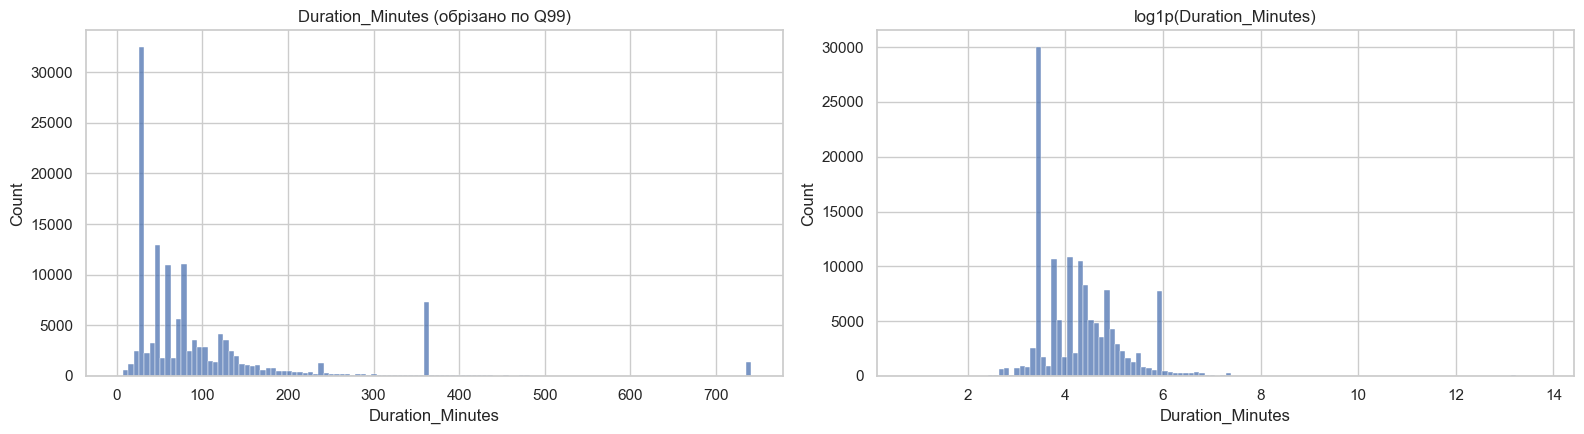

In [10]:
probs = [0.0, 0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 1.0]
q = df.approxQuantile("Duration_Minutes", probs, 0.0001)
display(pd.DataFrame({"квантиль": probs, "хвилин": q}).T)
skew = df.select(F.skewness("Duration_Minutes").alias("сирі"),
                 F.skewness(F.log1p("Duration_Minutes")).alias("log1p")).toPandas()
skew.index = ["коефіцієнт асиметрії"]
display(skew.round(2))

sample = df.select("Duration_Minutes", "Source").sample(fraction=0.02, seed=SEED).toPandas()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(sample["Duration_Minutes"].clip(upper=q[-3]), bins=120, ax=axes[0])
axes[0].set_title("Duration_Minutes (обрізано по Q99)")
sns.histplot(np.log1p(sample["Duration_Minutes"]), bins=120, ax=axes[1])
axes[1].set_title("log1p(Duration_Minutes)")
plt.tight_layout()
plt.show()

**Рішення:** ціль для моделі — **`Log_Duration = log1p(Duration_Minutes)`**.

**Аргументи:** сира тривалість має екстремальну асиметрію (максимум — роки), квадратична функція втрат лінійної регресії підлаштовувалась би під кілька тисяч «вічних» подій. Логарифм прибирає асиметрію і перетворює мультиплікативні ефекти (наприклад, «на магістралі вдвічі довше») на адитивні, які лінійна модель моделює природно. Прогноз у хвилинах отримується як `expm1(прогноз)`.

### 5.2 Шаблонні значення та заглушки

In [11]:
top = {}
for src in ["Source1", "Source2", "Source3"]:
    sub = df.filter(F.col("Source") == src)
    total = sub.count()
    t = sub.groupBy(F.round("Duration_Minutes", 0).alias("d")).count().orderBy(F.desc("count")).limit(6).toPandas()
    top[src] = [f"≈{d:g} хв — {100 * c / total:.1f}%" for d, c in zip(t["d"], t["count"])]
display(pd.DataFrame(top, index=[f"top-{i + 1}" for i in range(6)]))
n_placeholder = df.filter(is_placeholder_duration(F.col("Duration_Minutes"))).count()
print(f"Записів-заглушок 360 ± 0.05 хв: {n_placeholder:,} ({100 * n_placeholder / n_rows:.2f}% усіх)")

,Source1,Source2,Source3
top-1,≈360 хв — 9.8%,≈30 хв — 29.2%,≈30 хв — 23.2%
top-2,≈75 хв — 3.8%,≈45 хв — 14.1%,≈45 хв — 13.5%
top-3,≈30 хв — 3.5%,≈29 хв — 9.7%,≈60 хв — 9.5%
top-4,≈78 хв — 3.2%,≈60 хв — 9.1%,≈29 хв — 9.2%
top-5,≈29 хв — 2.2%,≈44 хв — 4.0%,≈44 хв — 3.5%
top-6,≈79 хв — 2.2%,≈75 хв — 2.4%,≈75 хв — 3.5%


Записів-заглушок 360 ± 0.05 хв: 349,718 (5.11% усіх)


**Рішення:**
* записи з тривалістю **360 ± 0.05 хв** (заглушка «6 годин» у Source1, включно з 359.98 / 360.02 через секунди) — **виключаємо**;
* шаблонні 30 / 45 / 60 хв у Source2/Source3 — **залишаємо**;
* область моделювання: **1 хв ≤ тривалість ≤ Q99(train)**; межа Q99 рахується **після** розбиття, лише на train.

**Аргументи:**
* у Source1 значення 360 хв трапляється в рази частіше за сусідні — це значення за замовчуванням, а не вимір; модель, навчена на ньому, вчиться передбачати дефолт джерела;
* шаблони Source2 — це **більшість** записів цього джерела; їх видалення знищило б джерело цілком. Вони відтворювані: модель вчить режим джерела через `Source_Year`;
* події довші за Q99 (~13 год) — переважно незакриті записи (тижні, роки); вони не відображають типовий вплив ДТП і домінували б у функції втрат навіть після логарифма. Межа з train, щоб не підглядати в test.

In [12]:
DECISIONS.append(("5. Ціль", "log1p(Duration); виключено заглушки 360±0.05 хв; область 1 хв…Q99(train)",
                  f"заглушок {n_placeholder:,}"))

## 6. Контроль витоку цільової змінної

Ознака має бути відома **на момент реєстрації ДТП**. Те, що описує наслідки ДТП, — витік.

In [13]:
desc = (df.select(*[F.avg(F.when(F.col(c) == 1, F.log1p("Duration_Minutes"))).alias(c) for c in DESC_PATTERNS])
        .toPandas().T.rename(columns={0: "сер. log-тривалість, якщо слово є"}))
desc["сер. log-тривалість, якщо слова немає"] = (
    df.select(*[F.avg(F.when(F.col(c) == 0, F.log1p("Duration_Minutes"))).alias(c) for c in DESC_PATTERNS]).toPandas().T[0])
desc["частка записів %"] = 100 * df.select(*[F.avg(c).alias(c) for c in DESC_PATTERNS]).toPandas().T[0]
desc.round(3)

,"сер. log-тривалість, якщо слово є","сер. log-тривалість, якщо слова немає",частка записів %
Desc_Closed,4.710,4.265,5.877
Desc_Blocked,3.979,4.381,22.244
Desc_Lane,4.068,4.351,20.883
Desc_Shoulder,3.939,4.314,6.093
Desc_Ramp_Exit,4.207,4.330,31.229
Desc_Slow_Traffic,4.524,4.235,19.676
Desc_Serious,3.977,4.294,0.663
Desc_Hazard,4.535,4.291,0.333


**Рішення — не використовуємо як ознаки:**

| Колонка | Причина |
|---|---|
| `End_Time` | тривалість = `End_Time − Start_Time` — пряма відповідь |
| `Severity` цього запису | теж наслідок ДТП, відомий лише після оцінки впливу на рух |
| прапорці з `Description` | опис фіксує наслідки (перекриття, затори): для класу «closed» тривалість систематично інша; у дослідженні ці ознаки штучно додавали R² |
| `ID`, `Start_Time` | ідентифікатор; зі `Start_Time` беремо лише похідні часові ознаки |

Історичні статистики **інших** ДТП на тій самій вулиці / в місті (зокрема частка тяжких ДТП там) — **не витік**: вони відомі заздалегідь. Їх формуємо в кроці 10 так, щоб запис ніколи не бачив власної цілі.

In [14]:
DECISIONS.append(("6. Витік", "без Description, End_Time, цілі іншої задачі", "8 прапорців Description не використано"))

## 7. Інженерія ознак

| Ознака | Як отримано | Чому |
|---|---|---|
| `Wind_Dir` | `Calm`/`CALM`, `Variable`/`VAR`, `North`/`N`… → один запис | 25 написань → 19 реальних значень; дублікати розпорошують статистику |
| `Weather_Group` + `Is_Windy` | 145 погодних станів → 8 груп за змістом; «/ Windy» — окремий прапорець | більшість станів — рідкісні комбінації; групування дає стабільні оцінки |
| `HourType` | година × (будні / вихідні), 48 категорій | годину пік мають лише будні; лінійна модель не бачить таких взаємодій сама |
| `Month_cat` | місяць як категорія | сезонність нелінійна (зима / літо / свята) |
| `DoW_sin`, `DoW_cos` | день тижня циклічно | неділя «поруч» із понеділком |
| `Source_Year` | джерело × рік | схема фіксації цілей змінювалась (кроки 2, 5) |
| `Street_Type` | тип дороги з назви | магістраль vs локальна вулиця — різні наслідки ДТП |
| `Light_Level` (з `main.py`) | 0–4 за чотирма twilight-ознаками | одна порядкова ознака замість чотирьох корельованих |

In [15]:
for c in ["Weather_Group", "Wind_Dir", "Street_Type"]:
    display(df.groupBy(c).count().orderBy(F.desc("count")).toPandas().set_index(c).T)

Weather_Group,Clear,Cloudy,Rain,Low_Visibility,Snow_Ice,Thunderstorm
count,3054705,2898636,466720,182638,158169,78840


Wind_Dir,CALM,S,W,N,SSW,WNW,E,NW,SW,VAR,WSW,SSE,NNW,SE,ESE,NE,NNE,ENE
count,1207336,547516,498627,394634,352247,343193,342851,334746,333834,333179,322709,318492,301954,266964,240631,234951,233246,232598


Street_Type,Local_Street,Interstate,Avenue_Blvd,Expressway,Route_Hwy,Other,US_Highway
count,2175576,1727938,875547,718821,707335,380987,253504


## 8. Розбиття train / valid / test — групове

**Рішення:** ключ групи — округлені до 0.001° координати (~100 м) + дата. Усі записи групи потрапляють в одну вибірку: **train 70% / valid 10% / test 20%** груп. Фолди target encoding (крок 10) — теж групові.

**Аргументи:**
* багато записів мають «близнюків» — та сама подія, повідомлена повторно, обидва напрямки руху, записи від різних джерел. При розбитті по рядках такі пари розходяться між train і test, і test перестає бути чесною оцінкою;
* **valid** потрібен для налаштування гіперпараметрів і порогів рішень на етапі навчання, щоб не підганяти їх під test;
* розбиття робимо **до** обчислення будь-яких статистик (межі викидів, target encoding, масштабування) — усі вони беруться лише з train.

In [16]:
grp = df.withColumn("_g", incident_group()).groupBy("_g").agg(F.count("*").alias("n"), F.countDistinct("Source").alias("ns"))
display(grp.agg(F.count("*").alias("груп «місце + день»"),
                F.sum(F.when(F.col("n") > 1, F.col("n")).otherwise(0)).alias("записів у групах з > 1 записом"),
                F.sum((F.col("ns") > 1).cast("int")).alias("груп з кількома джерелами")).toPandas())

df = (df.withColumn("_g", incident_group())
        .withColumn("_bucket", F.pmod(F.col("_g"), F.lit(100)))
        .withColumn("split", F.when(F.col("_bucket") < 20, "test").when(F.col("_bucket") < 30, "valid").otherwise("train"))
        .withColumn("fold", F.pmod(F.xxhash64(F.col("_g"), F.lit("fold")), F.lit(N_FOLDS)).cast("int"))
        .drop("_g", "_bucket"))

,груп «місце + день»,записів у групах з > 1 записом,груп з кількома джерелами
0,6349069,900200,71001


In [17]:
split_stats = (df.groupBy("split").agg(F.count("*").alias("записів"),
                                       F.expr("percentile_approx(Duration_Minutes, 0.5)").alias("медіана, хв"),
                                       F.round(F.avg(F.log1p("Duration_Minutes")), 4).alias("сер. log1p"))
               .toPandas().set_index("split").loc[["train", "valid", "test"]])
split_stats

,записів,"медіана, хв",сер. log1p
split,,,
train,4789382,64.72,4.2921
valid,683877,64.00,4.2894
test,1366449,64.50,4.2909


In [18]:
DECISIONS.append(("8. Розбиття", "групове (місце + день), 70/10/20, групові фолди TE", "див. таблицю вище"))

## 9. Викиди в ознаках

**Рішення:**
* вінсоризація (clip) неперервних ознак по **0.5% / 99.5% перцентилях train**;
* `log1p` для `Distance(mi)` після обрізання.

**Аргументи:** у погодних ознаках є фізично неможливі значення (температура ~200 °F, тиск 0, вітер > 1000 mph) — помилки датчиків. Видаляти рядки не варто (решта полів коректна), а обрізання по перцентилях залишає запис, але прибирає вплив помилки. Межі — лише з train. `Distance` має довгий правий хвіст і масу нулів — логарифм вирівнює масштаб. (`Precipitation` прибрано в кроці 4.)

In [19]:
NUM_CONT = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)"]
LOG_COLS = ["Distance(mi)"]
train_only = df.filter(F.col("split") == "train")
CLIP_BOUNDS = {c: (float(lo), float(hi)) for c, (lo, hi) in zip(NUM_CONT, train_only.approxQuantile(NUM_CONT, list(CLIP_Q), 0.0001))}
clip_share = train_only.select([F.round(100 * F.avg(((F.col(c) < lo) | (F.col(c) > hi)).cast("double")), 3).alias(c)
                                for c, (lo, hi) in CLIP_BOUNDS.items()]).toPandas().T[0]
display(pd.DataFrame({"нижня межа": {c: b[0] for c, b in CLIP_BOUNDS.items()},
                      "верхня межа": {c: b[1] for c, b in CLIP_BOUNDS.items()},
                      "% train-значень обрізано": clip_share}))
DUR_MAX = float(train_only.approxQuantile("Duration_Minutes", [0.99], 0.0001)[0])
DUR_MIN = 1.0
print(f"Q99 тривалості (train): {DUR_MAX:.1f} хв")
DECISIONS.append(("9. Викиди ознак", "clip 0.5/99.5% train; log1p Distance",
                  f"обрізано ≤ {clip_share.max():.2f}% значень кожної ознаки"))

,нижня межа,верхня межа,% train-значень обрізано
Distance(mi),0.00,9.562,0.505
Temperature(F),6.00,99.000,0.943
Humidity(%),9.00,100.000,0.402
Pressure(in),24.20,30.510,0.995
Visibility(mi),0.25,10.000,0.724
Wind_Speed(mph),0.00,25.000,0.422


Q99 тривалості (train): 741.5 хв


## 10. Високо-кардинальні ознаки: target encoding і частоти

**Рішення:** для ключів **вулиця** (`State|Street`), **місто**, **округ**, **поштовий індекс** обчислити:
* `TE_<key>_t_sev1 / t_sev3 / t_sev4` — згладжена частка ДТП класу 1 / 3 / 4 на цьому ключі;
* `TE_<key>_t_logdur` — згладжене середнє `log1p(тривалості)` (лише за записами області регресії, без заглушок);
* `Cnt_<key>` — `log1p` кількості **інших** train-записів з цим ключем (щільність аварій).

**Аргументи:**
* місто / округ / індекс / вулиця мають від тисяч до сотень тисяч значень — one-hot дав би сотні тисяч розріджених стовпців; target encoding стискає кожен ключ до кількох чисел;
* в обох задачах використовуємо статистики **обох** цілей: це історичні характеристики місця (там часто тяжкі / тривалі ДТП), відомі заздалегідь. У дослідженні, наприклад, середня тривалість на вулиці помітно допомагала класифікації;
* реалізація — бібліотечний **`sklearn.preprocessing.TargetEncoder`**: `target_type="multiclass"` для `Severity` (частки класів; частку класу 2 відкидаємо — частки в сумі дають 1) і `"continuous"` для log-тривалості; згладжування `smooth = 30`: $\frac{n\cdot\bar y_{key} + m\cdot\bar y}{n + m}$ — рідкісні ключі стягуються до загального середнього; невідомий у train ключ → загальне середнє. Частоти — `pandas.Series.value_counts`;
* чому не `pyspark.ml.feature.TargetEncoder`: на ключі з ~300 тис. значень (вулиці) його перетворення на 5 млн рядків не завершувалось за 10+ хв, тоді як sklearn робить усе кодування за ~2 хв;
* **захист від витоку:** енкодер навчається лише на train; рядки train кодуються **out-of-fold** — енкодером, навченим на інших 4 **групових** фолдах, тож запис ніколи не бачить власної цілі. Вбудований `cv` у sklearn ділить дані випадково — записи однієї ДТП від різних джерел «підглядали» б один за одним, тому фолди задаємо самі.

In [20]:
TE_KEYS = {"Street": "Key_Street", "City": "Key_City", "County": "Key_County", "Zip": "Key_Zip"}
in_domain = F.col("Duration_Minutes").between(DUR_MIN, DUR_MAX) & ~is_placeholder_duration(F.col("Duration_Minutes"))

prepared = (clip_and_log(df, CLIP_BOUNDS, LOG_COLS)
            .withColumn("Log_Duration", F.log1p(F.col("Duration_Minutes")))
            .withColumn("In_Reg_Domain", in_domain.cast("int"))
            .withColumn("label", (F.col("Severity") - 1).cast("double"))
            .withColumn("t_logdur", F.when(in_domain, F.col("Log_Duration"))))   # TE тривалості — лише якісні записи

splits = {s: prepared.filter(F.col("split") == s) for s in ["train", "valid", "test"]}
display(splits["train"].agg(*[F.countDistinct(k).alias(n) for n, k in TE_KEYS.items()]).toPandas()
        .rename(index={0: "унікальних ключів у train"}))
t0 = time.time()
key_cols = list(TE_KEYS.values())
frames = {s: d.select("ID", "Severity", "t_logdur", *key_cols, *(["fold"] if s == "train" else [])).toPandas()
          for s, d in splits.items()}
loc_codes = encode_locations(frames, TE_KEYS, smoothing=TE_SMOOTHING)
del frames
splits = {s: d.join(spark.createDataFrame(loc_codes[s]), "ID") for s, d in splits.items()}
TE_COLS = [c for c in loc_codes["train"].columns if c.startswith("TE_")]
CNT_COLS = [c for c in loc_codes["train"].columns if c.startswith("Cnt_")]
del loc_codes
print(f"Кодування локацій: {time.time() - t0:.0f} c; TE-ознак: {len(TE_COLS)}, частотних: {len(CNT_COLS)}")

,Street,City,County,Zip
унікальних ключів у train,291197,17334,2957,21484


Кодування локацій: 149 c; TE-ознак: 16, частотних: 4


In [21]:
# Регресія: лише записи області моделювання
for s in splits:
    splits[s] = splits[s].filter(F.col("In_Reg_Domain") == 1).persist(StorageLevel.MEMORY_AND_DISK)
n_split = {s: d.count() for s, d in splits.items()}
df.unpersist()
print(f"Записів в області регресії: {n_split}")
DECISIONS.append(("10. Target encoding", "sklearn TargetEncoder, OOF по групових фолдах, smooth = 30; + частоти",
                  f"{len(TE_COLS) + len(CNT_COLS)} числових ознак"))

Записів в області регресії: {'train': 4496355, 'valid': 642217, 'test': 1282718}


In [22]:
TARGET_COL = "Log_Duration" if TASK == "regression" else "Severity"
check = splits["valid"].select(
    *[(F.corr(f"TE_{n}_t_logdur", "Log_Duration") if TASK == "regression"
       else F.corr(F.col(f"TE_{n}_t_sev4"), (F.col("Severity") == 4).cast("double"))).alias(n)
      for n in TE_KEYS]).toPandas().T
check.columns = ["кореляція TE з ціллю на valid (чесна перевірка, статистики з train)"]
check.round(3)

,"кореляція TE з ціллю на valid (чесна перевірка, статистики з train)"
Street,0.313
City,0.280
County,0.271
Zip,0.290


## 11. Відбір ознак (фільтр-методи, лише train)

Моделі на цьому етапі не навчаються, тому відбираємо ознаки **без моделі**:

1. **Зв'язок із ціллю** — η (кореляційне відношення) з `Log_Duration`. Неперервні ознаки для цього розбиваються на 10 квантильних бінів (`QuantileDiscretizer`), тож враховуються й нелінійні залежності. Ознака без зв'язку (< `THR_ASSOC`) не може допомогти жодній моделі. Розрахунок — бібліотечними функціями: однофакторний ANOVA `sklearn.feature_selection.f_classif` → η² = F·df₁ / (F·df₁ + df₂).
2. **Надлишковість** — пари числових ознак з |r| > `THR_REDUNDANT` або категоріальних з Cramér's V > `THR_REDUNDANT` несуть одну й ту саму інформацію; з пари залишаємо ту, що сильніше пов'язана з ціллю.
3. **Константні стовпці** після кодування (крок 12).

**Пороги:**
* `THR_ASSOC = 0.01` — для η це η² = 0.0001, тобто ознака пояснює < 0.01% розкиду цілі; для Cramér's V — десята частина «малого» ефекту за Коеном (0.1). На 5 млн записів статистична значущість втрачає сенс (значущим буде майже все), тому критерій — **практична** величина ефекту;
* `THR_REDUNDANT = 0.9` — |r| > 0.9 означає > 81% спільної дисперсії: друга ознака майже нічого не додає. Фільтр консервативний — він не бачить, що ознака може дублювати **комбінацію** інших; остаточне звуження набору (наприклад, L1-регуляризацією) — справа етапу навчання.

In [23]:
NUM_UNITS = ["Start_Lat", "Start_Lng"] + NUM_CONT + TE_COLS + CNT_COLS
ORD_UNITS = ["Light_Level", "DayOfWeek"]          # мало значень — оцінюємо як категорії
CAT_UNITS = ["State", "Timezone", "Source_Year", "Wind_Dir", "Weather_Group", "Street_Type", "HourType", "Month_cat"]
BIN_UNITS = ROAD_BOOL + ["Is_Windy"]

train_df = splits["train"]
discretizer = QuantileDiscretizer(inputCols=NUM_UNITS, outputCols=[c + "_q" for c in NUM_UNITS], numBuckets=N_BINS,
                                  relativeError=0.001).fit(train_df)
# вузька таблиця (ціль + ознаки у дискретній формі) → pandas для бібліотечних статистик
assoc_pd = (discretizer.transform(train_df.select(TARGET_COL, *NUM_UNITS, *ORD_UNITS, *CAT_UNITS, *BIN_UNITS))
            .select(TARGET_COL, *[c + "_q" for c in NUM_UNITS], *ORD_UNITS, *CAT_UNITS, *BIN_UNITS).toPandas())


def association(col):
    if TASK == "regression":
        return eta(assoc_pd[col], assoc_pd["Log_Duration"])
    return cramers_v(assoc_pd[col], assoc_pd["Severity"])


t0 = time.time()
rows = []
for unit in NUM_UNITS + ORD_UNITS + CAT_UNITS + BIN_UNITS:
    kind = ("числова" if unit in NUM_UNITS else "порядкова" if unit in ORD_UNITS
            else "категоріальна" if unit in CAT_UNITS else "бінарна")
    rows.append({"ознака": unit, "тип": kind, "зв'язок з ціллю": association(unit + "_q" if unit in NUM_UNITS else unit)})
assoc = pd.DataFrame(rows).set_index("ознака")
prev = train_df.select(*[F.avg(c).alias(c) for c in BIN_UNITS]).toPandas().T[0]
assoc.loc[BIN_UNITS, "частка одиниць %"] = (100 * prev).round(4)
assoc["слабкий зв'язок"] = assoc["зв'язок з ціллю"] < THR_ASSOC
print(f"Зв'язок пораховано для {len(assoc)} ознак за {time.time() - t0:.0f} c; поріг = {THR_ASSOC}")
assoc.sort_values("зв'язок з ціллю", ascending=False).round(4)

Зв'язок пораховано для 51 ознак за 382 c; поріг = 0.01


,тип,зв'язок з ціллю,частка одиниць %,слабкий зв'язок
ознака,,,,
Source_Year,категоріальна,0.5369,NaN,False
Distance(mi),числова,0.4026,NaN,False
TE_Street_t_logdur,числова,0.2971,NaN,False
TE_Zip_t_logdur,числова,0.2765,NaN,False
TE_City_t_logdur,числова,0.2651,NaN,False
TE_County_t_logdur,числова,0.2565,NaN,False
State,категоріальна,0.2153,NaN,False
Pressure(in),числова,0.2019,NaN,False
HourType,категоріальна,0.1819,NaN,False


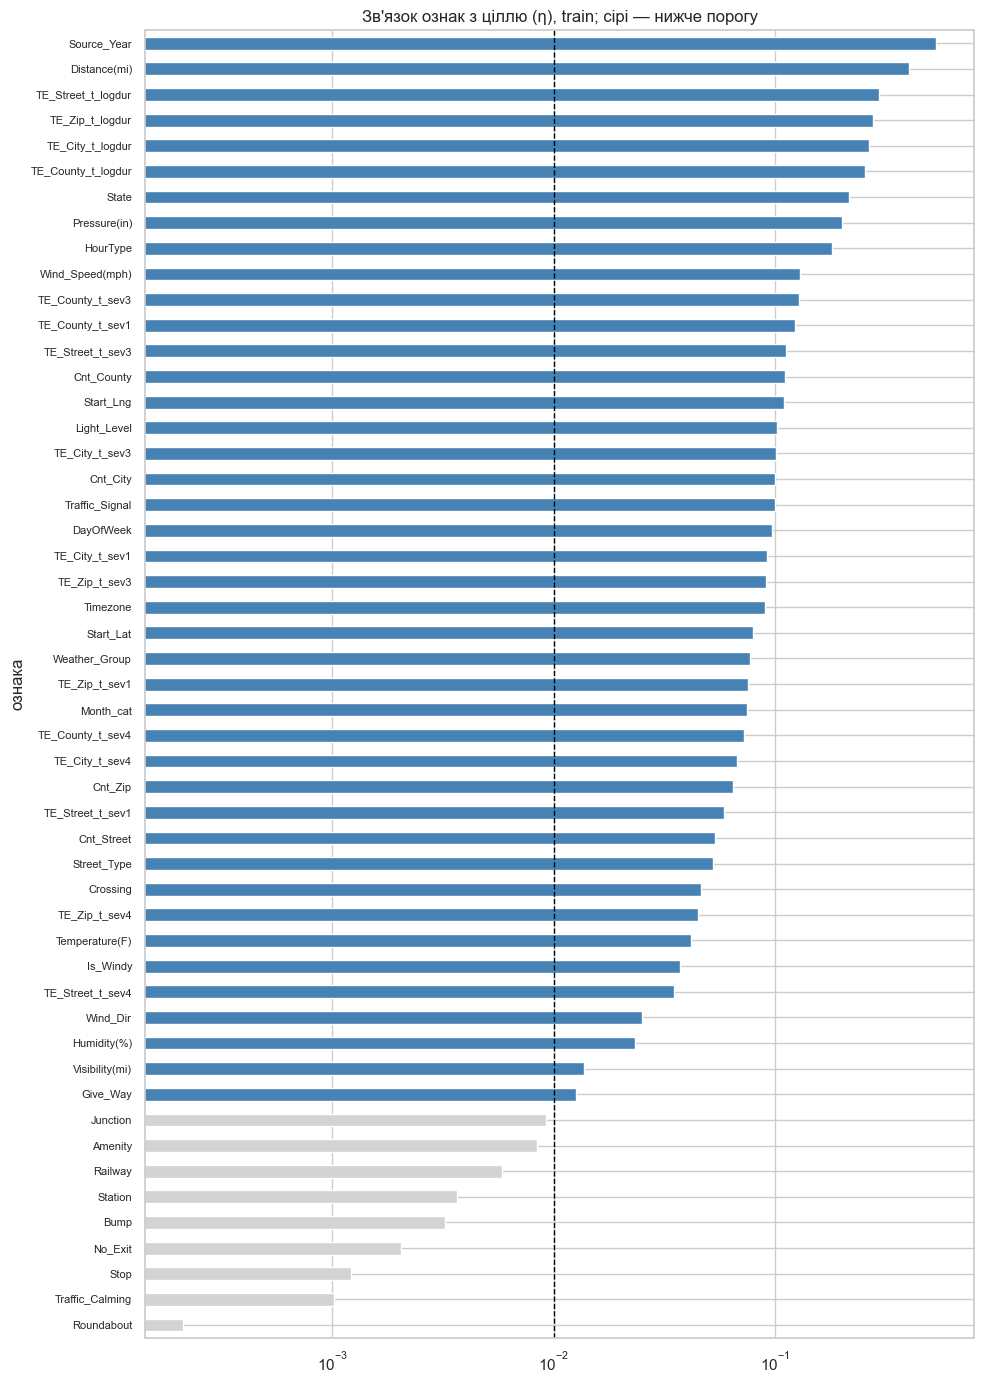

In [24]:
s = assoc["зв'язок з ціллю"].sort_values()
fig, ax = plt.subplots(figsize=(10, 14))
s.plot.barh(ax=ax, color=["lightgray" if v < THR_ASSOC else "steelblue" for v in s])
ax.axvline(THR_ASSOC, color="black", ls="--", lw=1)
ax.set_xscale("log")
ax.set_title(f"Зв'язок ознак з ціллю ({'η' if TASK == 'regression' else 'Cramér`s V'}), train; сірі — нижче порогу")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [25]:
# Надлишковість: числові пари (Pearson) і категоріальні пари (Cramér's V)
num_keep = [c for c in NUM_UNITS if not assoc.loc[c, "слабкий зв'язок"]]
vec = VectorAssembler(inputCols=num_keep, outputCol="_v").transform(train_df.select(num_keep)).select("_v")
corr = pd.DataFrame(Correlation.corr(vec, "_v").first()[0].toArray(), index=num_keep, columns=num_keep)
num_pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("сила").reset_index()
             .rename(columns={"level_0": "ознака 1", "level_1": "ознака 2"}).assign(міра="|Pearson r|"))
num_pairs["сила"] = num_pairs["сила"].abs()

cat_keep = [c for c in CAT_UNITS if not assoc.loc[c, "слабкий зв'язок"]]
cat_pairs = pd.DataFrame([{"ознака 1": a, "ознака 2": b, "сила": cramers_v(assoc_pd[a], assoc_pd[b]), "міра": "Cramér's V"}
                          for i, a in enumerate(cat_keep) for b in cat_keep[i + 1:]])
pairs = pd.concat([num_pairs, cat_pairs]).sort_values("сила", ascending=False)

redundant_drop = {}
for _, p in pairs[pairs["сила"] > THR_REDUNDANT].iterrows():
    a, b = p["ознака 1"], p["ознака 2"]
    if a in redundant_drop or b in redundant_drop:
        continue
    weaker = a if assoc.loc[a, "зв'язок з ціллю"] < assoc.loc[b, "зв'язок з ціллю"] else b
    redundant_drop[weaker] = f"дублює {b if weaker == a else a} ({p['міра']} = {p['сила']:.3f})"
print(f"Пар з силою > {THR_REDUNDANT}: {(pairs['сила'] > THR_REDUNDANT).sum()}; видаляємо як надлишкові: {len(redundant_drop)}")
pairs[pairs["сила"] > 0.8].round(3)

Пар з силою > 0.9: 4; видаляємо як надлишкові: 3


,ознака 1,ознака 2,сила,міра
0,State,Timezone,0.973,Cramér's V
358,TE_City_t_logdur,TE_Zip_t_logdur,0.949,|Pearson r|
278,TE_City_t_sev4,TE_Zip_t_sev4,0.943,|Pearson r|
357,TE_City_t_logdur,TE_County_t_logdur,0.929,|Pearson r|
363,TE_County_t_logdur,TE_Zip_t_logdur,0.887,|Pearson r|
247,TE_City_t_sev1,TE_Zip_t_sev1,0.886,|Pearson r|
244,TE_City_t_sev1,TE_County_t_sev1,0.885,|Pearson r|
263,TE_City_t_sev3,TE_Zip_t_sev3,0.853,|Pearson r|
260,TE_City_t_sev3,TE_County_t_sev3,0.829,|Pearson r|
275,TE_City_t_sev4,TE_County_t_sev4,0.805,|Pearson r|


In [26]:
weak = list(assoc.index[assoc["слабкий зв'язок"]])
selection = pd.DataFrame(
    [{"ознака": u, "рішення": "видалити", "причина": f"зв'язок з ціллю {assoc.loc[u, 'зв' + chr(39) + 'язок з ціллю']:.4f} < {THR_ASSOC}"} for u in weak]
    + [{"ознака": u, "рішення": "видалити", "причина": r} for u, r in redundant_drop.items()]).set_index("ознака")
KEEP_NUM = [c for c in NUM_UNITS if c not in weak and c not in redundant_drop]
KEEP_ORD = [c for c in ORD_UNITS if c not in weak]
KEEP_CAT = [c for c in CAT_UNITS if c not in weak and c not in redundant_drop]
KEEP_BIN = [c for c in BIN_UNITS if c not in weak]
print(f"Видалено {len(selection)} з {len(assoc)} ознак; залишено: числових {len(KEEP_NUM)}, порядкових {len(KEEP_ORD)}, "
      f"категоріальних {len(KEEP_CAT)}, бінарних {len(KEEP_BIN)}")
DECISIONS.append(("11. Відбір ознак", f"слабкий зв'язок < {THR_ASSOC}; дублікати > {THR_REDUNDANT}",
                  f"видалено {len(selection)} з {len(assoc)} вихідних ознак"))
del assoc_pd
selection

Видалено 12 з 51 ознак; залишено: числових 26, порядкових 2, категоріальних 7, бінарних 4


,рішення,причина
ознака,,
Amenity,видалити,зв'язок з ціллю 0.0084 < 0.01
Bump,видалити,зв'язок з ціллю 0.0032 < 0.01
Junction,видалити,зв'язок з ціллю 0.0093 < 0.01
No_Exit,видалити,зв'язок з ціллю 0.0020 < 0.01
Railway,видалити,зв'язок з ціллю 0.0058 < 0.01
Roundabout,видалити,зв'язок з ціллю 0.0002 < 0.01
Station,видалити,зв'язок з ціллю 0.0037 < 0.01
Stop,видалити,зв'язок з ціллю 0.0012 < 0.01
Traffic_Calming,видалити,зв'язок з ціллю 0.0010 < 0.01


## 12. Кодування і масштабування (Spark ML Pipeline, навчений лише на train)

| Тип | Перетворення | Чому |
|---|---|---|
| Категоріальні | `StringIndexer` (за частотою) → `OneHotEncoder(dropLast=True)` | лінійні моделі потребують числових ознак; найрідша категорія — референсна, щоб уникнути мультиколінеарності з вільним членом |
| Неперервні (погода, відстань) | + **квантильні біни** (10) → one-hot | лінійна модель отримує кусково-сталу поправку → нелінійні залежності (у дослідженні біни відстані були одними з найважливіших ознак) |
| Числові, порядкові, TE | `StandardScaler` (середнє 0, std 1) | коефіцієнти порівнянні, регуляризація й оптимізація працюють коректно |
| Бінарні | без змін (0/1) | вже у потрібній формі |

Останній етап — **`VarianceThresholdSelector(varianceThreshold=0)`**: прибирає стовпці, сталі на train (наприклад, порожній бін `[-inf, 0)` для невід'ємних ознак). Невідома в train категорія у valid/test → рядок відкидається (кількість показано нижче).

In [27]:
BIN_COLS = [c for c in ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)"]
            if c in KEEP_NUM]
SCALED = KEEP_NUM + (["Light_Level"] if "Light_Level" in KEEP_ORD else []) + (["DoW_sin", "DoW_cos"] if "DayOfWeek" in KEEP_ORD else [])

stages = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", stringOrderType="frequencyDesc", handleInvalid="skip") for c in KEEP_CAT]
stages.append(OneHotEncoder(inputCols=[f"{c}_idx" for c in KEEP_CAT], outputCols=[f"{c}_ohe" for c in KEEP_CAT], dropLast=True))
if BIN_COLS:
    stages += [QuantileDiscretizer(inputCols=BIN_COLS, outputCols=[f"{c}_bin" for c in BIN_COLS], numBuckets=N_BINS,
                                   relativeError=0.0005, handleInvalid="error"),
               OneHotEncoder(inputCols=[f"{c}_bin" for c in BIN_COLS], outputCols=[f"{c}_binohe" for c in BIN_COLS], dropLast=True)]
stages += [VectorAssembler(inputCols=SCALED, outputCol="num_vec"),
           StandardScaler(inputCol="num_vec", outputCol="num_scaled", withMean=True, withStd=True),
           VectorAssembler(inputCols=["num_scaled", *KEEP_BIN, *[f"{c}_ohe" for c in KEEP_CAT],
                                      *[f"{c}_binohe" for c in BIN_COLS]], outputCol="features_all"),
           VarianceThresholdSelector(featuresCol="features_all", outputCol="features", varianceThreshold=0.0)]
t0 = time.time()
prep_model = Pipeline(stages=stages).fit(splits["train"])
LABELS = {c: list(m.labels) for c, m in zip(KEEP_CAT, prep_model.stages[:len(KEEP_CAT)])}
BIN_SPLITS = dict(zip(BIN_COLS, prep_model.stages[len(KEEP_CAT) + 1].getSplitsArray())) if BIN_COLS else {}
scaler = [s for s in prep_model.stages if hasattr(s, "std") and hasattr(s, "mean")][0]

FEATURE_NAMES = (SCALED + KEEP_BIN + [f"{c}={lab}" for c in KEEP_CAT for lab in LABELS[c][:-1]]
                 + [f"{c} in [{sp[j]:.4g}, {sp[j + 1]:.4g})" for c, sp in BIN_SPLITS.items() for j in range(len(sp) - 2)])
probe = prep_model.transform(splits["train"].limit(1)).first()["features_all"]
assert probe.size == len(FEATURE_NAMES), (probe.size, len(FEATURE_NAMES))
selected = set(prep_model.stages[-1].selectedFeatures)
CONST_COLS = [n for i, n in enumerate(FEATURE_NAMES) if i not in selected]
FINAL_FEATURES = [n for i, n in enumerate(FEATURE_NAMES) if i in selected]
print(f"Pipeline навчено за {time.time() - t0:.0f} c; ознак до VarianceThresholdSelector: {len(FEATURE_NAMES)}, "
      f"після: {len(FINAL_FEATURES)}")

Pipeline навчено за 60 c; ознак до VarianceThresholdSelector: 232, після: 230


In [28]:
encoded = {s: prep_model.transform(d) for s, d in splits.items()}
lost = {s: n_split[s] - encoded[s].count() for s in ["valid", "test"]}
print(f"Константних стовпців: {len(CONST_COLS)} {CONST_COLS}")
print(f"Відкинуто рядків через невідомі категорії: {lost}")
print(f"Підсумково ознак: {len(FINAL_FEATURES)}")
groups = pd.Series({"масштабовані числові / TE / порядкові": len([f for f in FINAL_FEATURES if f in SCALED]),
                    "бінарні": len([f for f in FINAL_FEATURES if f in KEEP_BIN]),
                    **{f"one-hot {c}": len([f for f in FINAL_FEATURES if f.startswith(c + "=")]) for c in KEEP_CAT},
                    "квантильні біни": len([f for f in FINAL_FEATURES if " in [" in f])})
DECISIONS.append(("12. Кодування", "one-hot (dropLast), біни, StandardScaler; без константних стовпців",
                  f"{len(FINAL_FEATURES)} ознак, константних прибрано {len(CONST_COLS)}"))
groups.to_frame("стовпців")

Константних стовпців: 2 ['Distance(mi) in [-inf, 0)', 'Wind_Speed(mph) in [-inf, 0)']
Відкинуто рядків через невідомі категорії: {'valid': 0, 'test': 0}
Підсумково ознак: 230


,стовпців
масштабовані числові / TE / порядкові,29
бінарні,4
one-hot State,48
one-hot Source_Year,21
one-hot Wind_Dir,17
one-hot Weather_Group,5
one-hot Street_Type,6
one-hot HourType,47
one-hot Month_cat,11
квантильні біни,42


## 13. Експорт готових даних

`data/processed/regression/{train,valid,test}/part-*.parquet`:
* ознаки — по стовпцю на ознаку (float32), вже закодовані й масштабовані;
* **`Log_Duration`** — ціль для навчання; `Duration_Minutes` — для метрик у хвилинах (`expm1(прогноз)`); `ID` — для трасування.

`metadata.json` — усі параметри обробки (межі clip, біни, параметри scaler, категорії, TE, рішення відбору), щоб так само перетворити нові дані.

Spark на Windows не пише файли без `winutils.exe`, тому експорт — через pandas/pyarrow частинами.

In [29]:
N_CHUNKS = {"train": 14, "valid": 2, "test": 4}


def export(d, name, n_chunks):
    out_dir = OUTPUT_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    for old in out_dir.glob("part-*.parquet"):
        old.unlink()
    flat = (d.withColumn("_f", vector_to_array("features", "float32"))
            .select("ID", *[F.col("_f")[i].alias(n) for i, n in enumerate(FINAL_FEATURES)], F.col("Log_Duration").cast("double").alias("Log_Duration"), F.col("Duration_Minutes").cast("double").alias("Duration_Minutes"),
                    F.pmod(F.xxhash64("ID"), F.lit(n_chunks)).alias("_chunk")))
    rows = 0
    for k in range(n_chunks):
        part = flat.filter(F.col("_chunk") == k).drop("_chunk").toPandas()
        part.to_parquet(out_dir / f"part-{k:03d}.parquet", index=False)
        rows += len(part)
    size = sum(p.stat().st_size for p in out_dir.glob("*.parquet")) / 2**20
    print(f"{name}: {rows:,} рядків, {n_chunks} файлів, {size:.0f} MB")
    return rows


t0 = time.time()
saved = {s: export(encoded[s], s, N_CHUNKS[s]) for s in ["train", "valid", "test"]}
print(f"Експорт: {time.time() - t0:.0f} c")

train: 4,496,355 рядків, 14 файлів, 335 MB


valid: 642,217 рядків, 2 файлів, 44 MB


test: 1,282,718 рядків, 4 файлів, 88 MB
Експорт: 406 c


In [30]:
metadata = {
    "task": TASK, "source": DATA_PATH, "seed": SEED, "target": "Log_Duration = log1p(Duration_Minutes)", "prediction_to_minutes": "expm1(prediction)",
    "rows": saved,
    "split": "group split by incident_group (lat/lng rounded to 3 dp + date): train 70%, valid 10%, test 20%",
    "regression_domain_minutes": [DUR_MIN, DUR_MAX], "placeholder_duration": "360 ± 0.05 min (excluded from regression and from TE of duration)",
    "feature_names": FINAL_FEATURES,
    "numeric_scaled": SCALED, "binary": KEEP_BIN, "categorical": KEEP_CAT, "category_labels": LABELS,
    "binned": {c: [float(x) for x in sp] for c, sp in BIN_SPLITS.items()},
    "clip_bounds": CLIP_BOUNDS, "log1p_columns": LOG_COLS,
    "scaler": {"mean": dict(zip(SCALED, map(float, scaler.mean.toArray()))), "std": dict(zip(SCALED, map(float, scaler.std.toArray())))},
    "target_encoding": {"implementation": "sklearn.preprocessing.TargetEncoder, out-of-fold by group folds",
                        "keys": TE_KEYS, "targets": {"Severity": "multiclass (classes 1, 3, 4)", "t_logdur": "continuous"},
                        "smoothing": TE_SMOOTHING, "folds": N_FOLDS},
    "snapshots": "same source, lat/lng rounded to 4 dp, same street, same direction, start gaps <= 15 min: "
                 + ("keep the version with the latest End_Time" if TASK == "regression"
                    else "groups with conflicting Severity dropped; otherwise keep the version with the latest End_Time"),
    "unknown_values": {"dropped_rows": ["no weather station data (incl. 'N/A Precipitation')", "unknown wind speed with known direction",
                                        "unknown twilight", "unknown street"],
                       "restored": "wind speed = 0 when calm and speed unknown", "dropped_features": ["Precipitation(in)"]},
    "feature_selection": {"assoc_threshold": THR_ASSOC, "redundancy_threshold": THR_REDUNDANT,
                          "dropped": selection["причина"].to_dict(), "constant_columns": CONST_COLS},
    "excluded_for_leakage": ["Description keyword flags", "End_Time", "other task target of the same record"],
    "unseen_source_year": {
        "rule": "unseen Source_Year (e.g. Source1_2026) -> replace with the latest Source_Year of the same source seen in train before encoding; do not drop the record and do not leave all Source_Year dummies at zero (that is the reference category Source3_2016 with a different labelling scheme)",
        "latest_per_source": {s: max(l for l in LABELS["Source_Year"] if l.startswith(s + "_"))
                              for s in sorted({l.split("_")[0] for l in LABELS["Source_Year"]})},
        "evidence": "out-of-time check (classification, test rows of Source1_2023 with a model trained without 2023): accuracy 0.969 / F1 class 4 0.311 with the rule vs 0.744 / 0.366 with the reference category (21% of predictions became class 3, which Source1 does not use since 2021); in-time model: 0.969 / 0.324. Valid only while the source keeps its labelling scheme",
    },
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
DECISIONS.append(("Експорт", "parquet (float32) + metadata.json", f"{saved}"))
print("metadata.json збережено")

metadata.json збережено


In [31]:
check = pd.read_parquet(next((OUTPUT_DIR / "train").glob("part-*.parquet")))
print("Форма одного файлу train:", check.shape)
print("Пропусків:", int(check.isna().sum().sum()))
check.sample(5, random_state=SEED).iloc[:, list(range(8)) + list(range(-6, 0))].round(3)

Форма одного файлу train: (320512, 233)
Пропусків: 0


,ID,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),"Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)",Log_Duration,Duration_Minutes
185867,A-6830718,0.716,0.505,0.905,-0.676,0.921,-0.267,0.415,0.0,1.0,0.0,0.0,4.663,105.00
7286,A-1556815,-0.235,0.745,-0.557,-0.357,-1.406,-0.142,0.415,0.0,0.0,0.0,1.0,4.102,59.47
112151,A-6705056,-0.507,-1.287,2.068,-0.144,-2.152,-0.952,0.415,0.0,0.0,0.0,0.0,4.735,112.83
52212,A-6839233,-0.413,-1.323,0.654,-0.730,0.482,-0.838,0.415,0.0,0.0,0.0,0.0,4.692,108.02
90501,A-4928329,-0.465,0.434,2.620,0.548,1.008,-0.017,0.415,0.0,0.0,0.0,0.0,5.209,181.95


## Зведення рішень

In [32]:
pd.DataFrame(DECISIONS, columns=["Крок", "Рішення", "Результат на даних"]).set_index("Крок")

,Рішення,Результат на даних
Крок,,
1–2. Первинна обробка + повернення колонок,"конвеєр main.py; +Source, Street_Type, ключ ву...","7,728,394 → 7,579,570 рядків"
3. Знімки однієї події,з групи знімків — версія з найпізнішим End_Time,"7,579,570 → 7,119,525 рядків"
4. Невідомі значення,видалено записи з вигаданими значеннями; штиль...,"7,119,525 → 6,839,708 рядків"
5. Ціль,log1p(Duration); виключено заглушки 360±0.05 х...,"заглушок 349,718"
6. Витік,"без Description, End_Time, цілі іншої задачі",8 прапорців Description не використано
8. Розбиття,"групове (місце + день), 70/10/20, групові фолд...",див. таблицю вище
9. Викиди ознак,clip 0.5/99.5% train; log1p Distance,обрізано ≤ 0.99% значень кожної ознаки
10. Target encoding,"sklearn TargetEncoder, OOF по групових фолдах,...",20 числових ознак
11. Відбір ознак,слабкий зв'язок < 0.01; дублікати > 0.9,видалено 12 з 51 вихідних ознак


## Висновки

**Готовий датасет:** `data/processed/regression/` — train **4 496 355**, valid **642 217**, test **1 282 718** записів, **230 ознак** (float32, закодовані й масштабовані), ціль `Log_Duration`, пропусків немає. Медіана тривалості у трьох вибірках однакова (~64–65 хв) — розбиття не зсунуте.

| Крок | Що зроблено | Чому |
|---|---|---|
| Первинна обробка | конвеєр `main.py`: 7 728 394 → 7 579 570 записів | узгодженість з рештою проєкту |
| Знімки однієї події | прибрано **460 045** повторних версій (6.07%; у Source1 — 10.6%), з кожної групи залишено версію з найпізнішим `End_Time` | збирач зберігав кожне оновлення події як новий запис: у групах той самий початок (79%) і протяжність (78%), але різний кінець (83%) — остаточна версія містить повну тривалість |
| Невідомі значення | видалено 279 817 записів (3.93%) з вигаданими значеннями (без даних метеостанції, швидкість вітру при відомому напрямку, twilight, вулиця); для 365 090 записів зі штилем відновлено швидкість **0**; ознаку `Precipitation` прибрано (невідома в 30% записів, у 2016–2018 — у ~90%) | заповнені медіаною / «Unknown» / «ніч» значення — шум, який модель не відрізнить від справжніх даних |
| Ціль | `log1p(Duration)`: асиметрія 59.6 → 1.29; виключено 349 718 заглушок 360 ± 0.05 хв; область 1 хв … Q99(train) = 741.5 хв | лінійна модель на сирих хвилинах підлаштовувалась би під «вічні» події та дефолти джерела |
| Витік | без `End_Time`, `Severity`, `Description` | наслідки ДТП, невідомі на момент реєстрації |
| Розбиття | групове «місце + день», 70 / 10 / 20 | близькі в часі й місці записи не розходяться між train і test |
| Викиди | clip 0.5 / 99.5% train (обрізано ≤ 1% значень), `log1p(Distance)` | помилки датчиків, довгі хвости |
| Локації | `sklearn.preprocessing.TargetEncoder` (OOF по групових фолдах) + частоти; кореляція TE вулиці з ціллю на valid — 0.31 | сотні тисяч значень ключів → кілька інформативних чисел без витоку |
| Відбір ознак | видалено 12 з 51: 9 дорожніх прапорців без зв'язку з тривалістю (η < 0.01), `Timezone` (дублює `State`, V = 0.973), 2 дублікати TE (r > 0.94) | ознака без зв'язку чи дублікат не додає інформації |
| Кодування | one-hot, квантильні біни, `StandardScaler`, `VarianceThresholdSelector` прибрав 2 порожні біни | формат для лінійних моделей, нелінійні ефекти через біни |

**Найсильніше пов'язані з тривалістю ознаки:** `Source_Year` (η = 0.54 — режими фіксації часу завершення в джерелах), відстань (0.40), середня тривалість на вулиці / індексі / місті / в окрузі (0.26–0.30), штат (0.22), тиск (0.20), година × будні/вихідні (0.18).

**Нові дані: невідомий рік джерела.** Ознака `Source_Year` прив'язана до років, які були в train (до 2023). Для запису з новим роком (наприклад, `Source1_2026`) перед кодуванням **замінюємо `Source_Year` на останній відомий рік того ж джерела** (`Source1_2023`, `Source2_2022`, `Source3_2022`; збережено в `metadata.json` → `unseen_source_year`). Без цього правила `StringIndexer(handleInvalid="skip")` відкинув би запис, а якщо залишити всі one-hot стовпці нулями — модель сприйняла б запис як референсну категорію `Source3_2016` з іншою схемою розмітки. Правило коректне, лише поки джерело не змінює схему розмітки (як Source1 у 2021 р.), тому на нових даних потрібні моніторинг розподілу прогнозів і періодичне перенавчання.

**Рекомендації для етапу навчання:**
* навчати на `train`, гіперпараметри (регуляризація, функція втрат) підбирати на `valid`, `test` — лише для фінальної оцінки;
* ціль — `Log_Duration`, прогноз у хвилинах — `expm1(прогноз)`; метрики: R² і RMSE у лог-шкалі, MAE / медіанна похибка у хвилинах (`Duration_Minutes`);
* частина розкиду цілі — шаблони джерел (≈30 / 45 / 60 хв у Source2/3), тож очікувана межа якості лінійної моделі помірна; функція втрат Хьюбера може зменшити абсолютні похибки.

In [33]:
for d in splits.values():
    d.unpersist()
spark.stop()